In [3]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

from skimage.color import rgb2lab, lab2rgb

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from numpy.random import random

# Spectrum Transfer Model

In [4]:
st_extend_20 = 0
st_extend_21 = 1
st_extend_30 = 2

class SpectrumTransfer:
    
    def __init__(self):
        self.extend_mode = 0
        self.pca_eigenvectors = None
        self.pca_mean = None
        self.M = None
        self.TransM = None
        self.TransMin = 0.0
        self.TransMax = 1.0
        
    def get_extend_color(self, src_rgb):
        
        extend = None

        if self.extend_mode == 0:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2)])
        elif self.extend_mode == 1:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2]])
        elif self.extend_mode == 2:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2], np.power(src_rgb[:,0],3), np.power(src_rgb[:,1],3), np.power(src_rgb[:,2],3)])

        return extend
    
    def prepare(self):
        self.TransM = np.dot(self.M.T, self.pca_eigenvectors)
        return
     
    def train(self, extend_mode, train_spec, train_color, pca_comps=6):
        self.extend_mode = extend_mode
        
        pca = PCA(n_components=pca_comps, whiten=False)
        pca.fit(train_spec)
        
        self.pca_eigenvectors = pca.components_
        self.pca_mean = pca.mean_

        trans_pca_a = pca.transform(train_spec)
        trans_extend_c = self.get_extend_color(train_color)

        self.M = np.dot(trans_pca_a.T, pinv(trans_extend_c))

        self.prepare()
        
        c = np.arange(256)
        all_color = np.array(np.meshgrid(c, c, c)).T.reshape(-1,3)

        self.TransMin = 0.0
        self.TransMax = 1.0
        
#         min_v = 100.0
#         max_v = -100.0

#         split_num = 64
#         batch_size = int(all_color.shape[0] / split_num)

#         for n in range(64):
#             test_c = all_color[n * batch_size: (n+1) *batch_size, :]
#             test_s = self.transfer(test_c)
#             batch_min = np.min(test_s)
#             batch_max = np.max(test_s)

#             min_v = min(min_v, batch_min)
#             max_v = max(max_v, batch_max)

#         self.TransMin = min_v
#         self.TransMax = max_v
        
        return
    
    def save(self, setup_file):
        np.savez(setup_file, a=self.M, b=self.pca_eigenvectors, c=self.pca_mean, d=np.array([self.TransMin,self.TransMax]), e=np.array([self.extend_mode]))

        
    def save_files(self, setup_path):
        np.save(os.path.join(setup_path, "spec_a.npy"), self.M)
        np.save(os.path.join(setup_path, "spec_b.npy"), self.pca_eigenvectors)
        np.save(os.path.join(setup_path, "spec_c.npy"), self.pca_mean)
        np.save(os.path.join(setup_path, "spec_d.npy"), np.array([self.TransMin,self.TransMax]))
        np.save(os.path.join(setup_path, "spec_e.npy"), np.array([self.extend_mode]))
        
    def load(self, setup_file):
        weight = np.load(setup_file)
        
        self.M = weight["a"]
        self.pca_eigenvectors = weight["b"]
        self.pca_mean = weight["c"]
        
#         self.TransMin = weight['d'][0]
#         self.TransMax = weight['d'][1]
        
        self.extend_mode = weight['e'][0]
        
        self.prepare()
        
        return
 
    def transfer1D(self, src_data):
        
        src_data = src_data.astype(np.float32)

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)

        return tar_sepc
    
    def transfer(self, src_data):
        
        src_data = src_data.astype(np.float32)
        
        src_shape = src_data.shape

        if len(src_shape) >= 3:
            src_data = src_data.reshape(-1, src_shape[-1])

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean

        if len(src_shape) >= 3:
            tar_sepc = tar_sepc.reshape(src_shape[0:-1] + tuple([self.pca_mean.shape[0]]))
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)
        
        return tar_sepc

# Color Reproduce Model

In [5]:
class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        dims = len(img_spec.shape)
        
        if dims == 2:
            hw,c = img_spec.shape
        elif dims == 3:
            h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v) * 255.0
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0 * 255.0
        
        if dims == 2:
            img_rep_xyz = img_rep_xyz.reshape(hw, 1, 3).astype('uint8')
        elif dims == 3:
            img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
            
        img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
        if dims == 2:
            img_rep_rgb = img_rep_rgb.reshape(hw, 3)
            
        return img_rep_rgb

# Functions

In [6]:
def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src)
    lab_test = rgb2lab(rgb_test)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

In [7]:
# standard data
# 24 std, wli, nbi color

std24 = np.load('data_std.npy')
wlis = np.load('data_wli.npy')
nbis = np.load('data_nbi.npy')

In [8]:
# initial SpectrumTransfer and ColorReproducer

transfer = SpectrumTransfer()
transfer.load("weight.npz")

reproducer = ColorReproducer()
reproducer.load('cr_weights')

In [9]:
# olympus lighting

light_wli = np.loadtxt('Light_WLI.txt').T
light_nbi = np.loadtxt('Light_NBI.txt').T

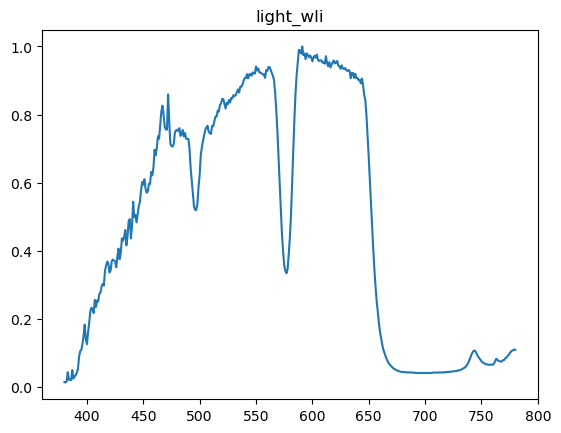

In [10]:
plt.title('light_wli')
plt.plot(np.arange(380,781), light_wli)
plt.show()

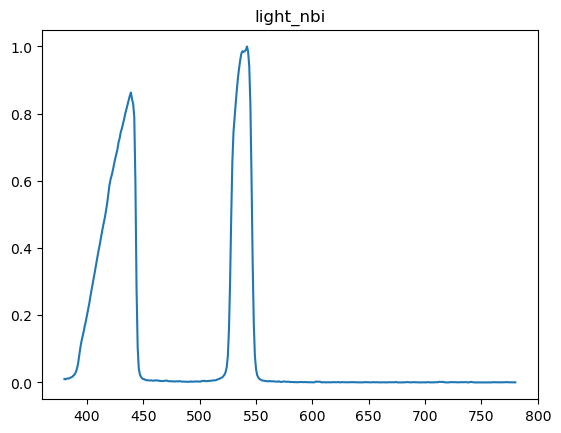

In [11]:
plt.title('light_nbi')
plt.plot(np.arange(380,781), light_nbi)
plt.show()

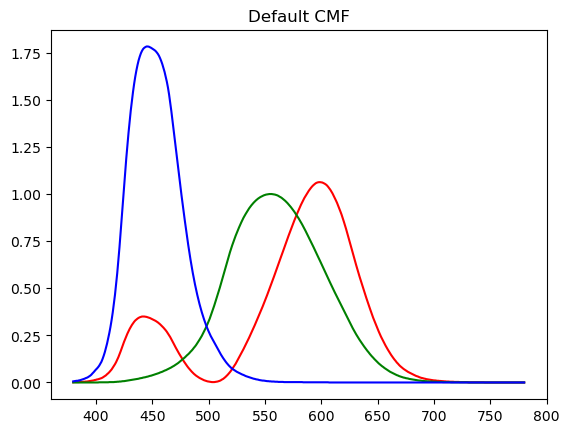

In [12]:
plt.title('Default CMF')
plt.plot(np.arange(380,781), reproducer.cmf[:,0], 'r')
plt.plot(np.arange(380,781), reproducer.cmf[:,1], 'g')
plt.plot(np.arange(380,781), reproducer.cmf[:,2], 'b')
plt.show()

In [13]:
# transfer wli to spectrum

wli_spec = transfer.transfer1D(wlis)

In [14]:
# set olympus wli lighting
reproducer.light_spec = light_wli
reproducer.prepare()

# simulate wli from spectrum
sim_wli = reproducer.reproduce(wli_spec, 1.0, False, None)

errs = cal_delta_e_cie2000_rgb(wlis, sim_wli)

print('average cie2000', np.average(errs))

AttributeError: module 'numpy' has no attribute 'asscalar'

# Optimize Gain (base on WLI reproduce)

In [15]:
# Optimize Gain

def objective(gain):
     
    sim_wli = reproducer.reproduce(wli_spec, gain, False, None)

    errs = cal_delta_e_cie2000_rgb(wlis, sim_wli)

    return np.average(errs)

# define range for input
r_min, r_max = 0.0, 10.0

# define the bounds on the search
bounds = [[r_min, r_max]]

# perform the simulated annealing search
result = dual_annealing(objective, bounds)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('solution', solution)
print('average cie2000', evaluation)

AttributeError: module 'numpy' has no attribute 'asscalar'

In [14]:
# update

best_gain = solution[0]

# Optimize CMF (base on WLI reproduce)

In [15]:
# Optimize cmf

base_cmf = reproducer.cmf

def objective(cmf_ratio):
    
    tar_cmf = base_cmf.copy()
    
    for i in range(3):
        tar_cmf[:,i] = base_cmf[:,i] * cmf_ratio[i]
    
    reproducer.cmf = tar_cmf
    reproducer.prepare()
    
    sim_wli = reproducer.reproduce(wli_spec, best_gain, False, None)

    errs = cal_delta_e_cie2000_rgb(wlis, sim_wli)

    return np.average(errs)

# define range for input
r_min, r_max = 0.1, 2.0

# define the bounds on the search
bounds = [[r_min, r_max]]*3

# perform the simulated annealing search
result = dual_annealing(objective, bounds)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('solution', solution)
print('average cie2000', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 6065
solution [1.33713394 1.948869   0.1627403 ]
average cie2000 7.966140108136912


In [16]:
# update

best_cmf_ratio = solution
tar_cmf = base_cmf.copy()

for i in range(3):
    tar_cmf[:,i] = base_cmf[:,i] * best_cmf_ratio[i]
    
reproducer.cmf = tar_cmf
reproducer.prepare()

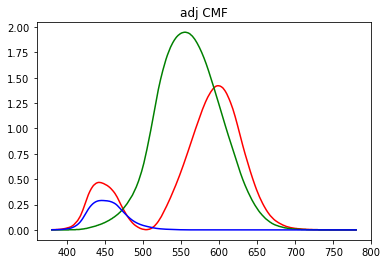

In [17]:
plt.title('adj CMF')
plt.plot(np.arange(380,781), reproducer.cmf[:,0], 'r')
plt.plot(np.arange(380,781), reproducer.cmf[:,1], 'g')
plt.plot(np.arange(380,781), reproducer.cmf[:,2], 'b')
plt.show()

In [18]:
img = cv2.imread('en_img.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

spec = transfer.transfer(img);

rep_img = reproducer.reproduce(spec, best_gain, False, None)

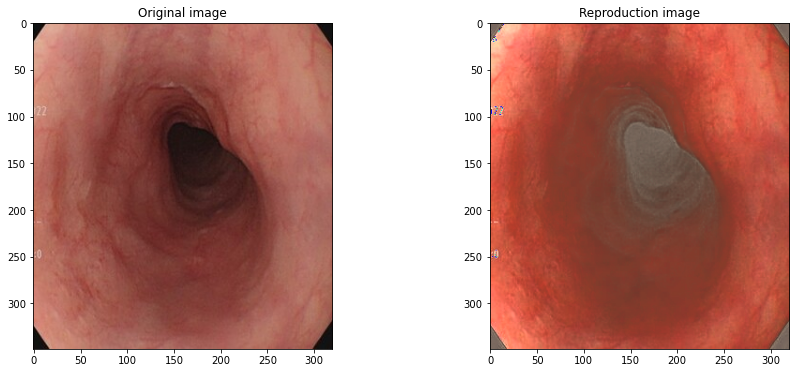

In [19]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

# Optimize NBI (base on WLI to NBI)

In [21]:
# if use 401 band, will take long time Optimize
# set light gap, avoid use to many variable
# set light_gap = 1, 401 variables
# set light_gap = 10, 41 variables
# set light_gap = 40, 11 variables

light_gap = 10

def interp_light(light_spec_gap):
    
    if light_gap == 1:
        return light_spec_gap
    
    x = np.arange(380,781,light_gap)
    
    xvals = np.arange(380,781)
    
    light_spec_1nm = np.interp(xvals, x, light_spec_gap)  
    
    return light_spec_1nm

def objective(light_spec_gap):
    
    # update lighting and prepare
    reproducer.light_spec = interp_light(light_spec_gap)
    reproducer.prepare()
    
    sim_nbi = reproducer.reproduce(wli_spec, best_gain, False, None)

    errs = cal_delta_e_cie2000_rgb(nbis, sim_nbi)

    return np.average(errs)
 
# define range for input
r_min, r_max = 0.0, 10.0
# define the starting point as a random sample from the domain
# pt = r_min + rand(401) * (r_max - r_min)

# perform the l-bfgs-b algorithm search
# result = minimize(objective, pt, method='Nelder-Mead')
# result = minimize(objective, pt, method='Newton-CG')
# result = minimize(objective, pt, method='Powell')
# result = minimize(objective, pt, method='BFGS')

# define the bounds on the search
bounds = [[r_min, r_max]] * (int(400 / light_gap + 1))
# perform the simulated annealing search
result = dual_annealing(objective, bounds)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])
# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('average cie2000', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 84269
average cie2000 22.349520392093087


In [22]:
# update

reproducer.light_spec = interp_light(solution)
reproducer.prepare()

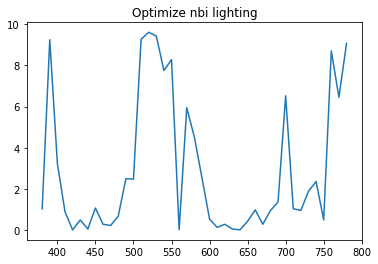

In [23]:
plt.title('Optimize nbi lighting')
plt.plot(np.arange(380,781), reproducer.light_spec)
plt.show()

In [24]:
sim_nbi = reproducer.reproduce(wli_spec, best_gain, False, None)

errs = cal_delta_e_cie2000_rgb(nbis, sim_nbi)

print(np.average(errs))

22.349520392093087


# transfer real image

In [25]:
img = cv2.imread('en_img.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

spec = transfer.transfer(img);

rep_img = reproducer.reproduce(spec, best_gain, False, None)

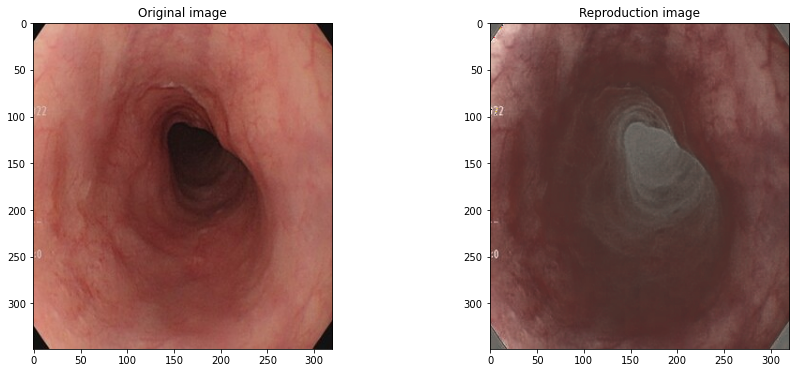

In [26]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

# Test Functions

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = np.arange(380,781,10)
y = np.random.rand(41)

xvals = np.arange(380,781)
yinterp = np.interp(xvals, x, y)

plt.plot(x, y, 'o')
plt.plot(xvals, yinterp, '-x')
plt.show()